In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
PROJECT_DIR=Path("/content/drive/MyDrive/Diabetes-Prediction")
ARTIFACTS_DIR=PROJECT_DIR / "artifacts"
X_train=pd.read_csv(ARTIFACTS_DIR / "X_train_8features.csv")
X_test = pd.read_csv(
    ARTIFACTS_DIR / "X_test_8features.csv"
)

y_train = pd.read_csv(
    ARTIFACTS_DIR / "y_train.csv"
)["Outcome"]

y_test = pd.read_csv(
    ARTIFACTS_DIR / "y_test.csv"
)["Outcome"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16000, 8)
X_test: (4000, 8)
y_train: (16000,)
y_test: (4000,)


In [11]:
#Train the logistic Regression model
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

print("Logistic Regression training completed.")
print("Iterations used:", model.n_iter_)

Logistic Regression training completed.
Iterations used: [15]


In [12]:
# Predicted classes: 0 or 1
y_pred = model.predict(X_test)

# Predicted probability of class 1 (Diabetic)
y_proba = model.predict_proba(X_test)[:, 1]

print("First 10 actual labels:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 diabetes probabilities:")
print(np.round(y_proba[:10], 3))

First 10 actual labels:
[1, 1, 1, 1, 0, 1, 0, 1, 0, 1]

First 10 predicted labels:
[1 1 1 1 0 1 0 1 0 1]

First 10 diabetes probabilities:
[1.    1.    1.    1.    0.005 1.    0.001 1.    0.001 0.981]


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

balanced_acc = balanced_accuracy_score(y_test, y_pred)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Recall:            {recall:.4f}")
print(f"F1-score:          {f1:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-diabetic", "Diabetic"],
    digits=4,
    zero_division=0
))

Accuracy:          0.9770
Precision:         0.9834
Recall:            0.9892
F1-score:          0.9863
Balanced accuracy: 0.9519

Detailed classification report:
              precision    recall  f1-score   support

Non-diabetic     0.9433    0.9145    0.9287       655
    Diabetic     0.9834    0.9892    0.9863      3345

    accuracy                         0.9770      4000
   macro avg     0.9633    0.9519    0.9575      4000
weighted avg     0.9768    0.9770    0.9769      4000



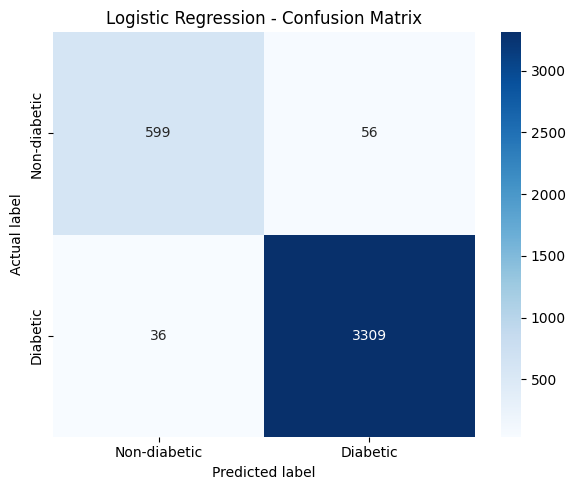

True Negatives (TN): 599
False Positives (FP): 56
False Negatives (FN): 36
True Positives (TP): 3309
Specificity: 0.9145


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-diabetic", "Diabetic"],
    yticklabels=["Non-diabetic", "Diabetic"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

specificity = tn / (tn + fp) if (tn + fp) else 0
print(f"Specificity: {specificity:.4f}")

In [15]:
import joblib

MODEL_PATH = ARTIFACTS_DIR / "diabetes_logistic_regression (8).joblib"

joblib.dump(model, MODEL_PATH)

print("Model saved to:", MODEL_PATH)

Model saved to: /content/drive/MyDrive/Diabetes-Prediction/artifacts/diabetes_logistic_regression (8).joblib


In [16]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Balanced Accuracy": balanced_acc,
    "Specificity": specificity
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

display(metrics_df.round(4))

metrics_df.to_csv(
    ARTIFACTS_DIR / "logistic_regression_metrics (8).csv",
    index=False
)

print("Evaluation metrics saved.")

,Metric,Score
0,Accuracy,0.9770
1,Precision,0.9834
2,Recall,0.9892
3,F1-score,0.9863
4,Balanced Accuracy,0.9519
5,Specificity,0.9145


Evaluation metrics saved.
